# Same customer, three rows: six match keys against one customer table

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/dedupe-key-choice/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/dedupe-key-choice/demo.ipynb)

`Jonathan Smith`, `Smith, Jonathan` and `Jonathon Smith` are one customer. `Johnathan Smith` and the two
`John Smith` rows are three other people. Every dedupe script starts by choosing a KEY that decides which of those
rows are the same, and this notebook is not a deduper (see `dedup-pipeline`, Day 67, for merging and survivorship):
it runs six keys - exact, normalised, Soundex, Metaphone, Jaro-Winkler at 0.9, token-set ratio at 85 - over 45 CRM
rows belonging to 23 real customers, each row hand-labelled with who it is, and reports which pairs each key merges
that the others keep apart.

1. The engine
2. The scoreboard: splits and merges
3. What each key merges that the others do not
4. Two customers made one
5. Chained: merged without ever matching
6. The frontier
7. The ceiling
8. The chart
9. Try your own

## 1. The engine

Extracted from `explore.py` and `evidence.py` at build time. Every name is fictional. There is no randomness, so
every number below matches `evidence.txt` exactly.

In [1]:
from __future__ import annotations

# !pip install jellyfish==1.0.1 rapidfuzz==3.14.5   # uncomment on Colab / Binder
import re
import unicodedata
from itertools import combinations
from typing import Callable, Dict, List, Set, Tuple

import jellyfish as jf
import matplotlib.pyplot as plt
from rapidfuzz import fuzz


class _E:  # evidence.py refers to the engine as E
    pass

CORPUS: List[Tuple[str, str, str]] = [
    # one person, case / whitespace / punctuation
    ("Mary O'Brien", "P01", "as filed"),
    ("mary o'brien", "P01", "lower case"),
    ("MARY  O'BRIEN", "P01", "caps, double space"),
    ("Mary OBrien", "P01", "apostrophe dropped"),
    # one person, accents folded by a web form
    ("José Núñez", "P02", "as filed"),
    ("Jose Nunez", "P02", "accents stripped"),
    ("JOSE NUNEZ", "P02", "accents stripped, caps"),
    # one person, order swapped by an import
    ("Jonathan Smith", "P03", "as filed"),
    ("Smith, Jonathan", "P03", "family, given"),
    ("Jonathon Smith", "P03", "one-letter typo"),
    ("Jon Smith", "P03", "short form"),
    # a DIFFERENT person who shares the surname and a similar given name
    ("Johnathan Smith", "P04", "as filed"),
    ("John Smith", "P05", "as filed"),
    ("John Smith", "P06", "as filed (a second John Smith)"),
    # one person, nickname: no string key gets this
    ("William Jones", "P07", "as filed"),
    ("Bill Jones", "P07", "nickname"),
    ("W. Jones", "P07", "initial"),
    # phonetic twins who are the same person (a form that heard the name)
    ("Catherine Lee", "P08", "as filed"),
    ("Kathryn Lee", "P08", "spelled as heard"),
    # phonetic twins who are different people
    ("Catherine Leigh", "P09", "as filed"),
    ("Stephen Baker", "P10", "as filed"),
    ("Steven Baker", "P10", "spelled as heard"),
    ("Stefan Becker", "P11", "as filed (sounds like P10 to Soundex)"),
    # hyphen vs space vs one surname kept
    ("Anna Müller-Schmidt", "P12", "as filed"),
    ("Anna Muller Schmidt", "P12", "hyphen to space, umlaut folded"),
    ("Anna Mueller-Schmidt", "P12", "umlaut transliterated"),
    ("Anna Schmidt", "P12", "one surname kept"),
    ("Anna Müller", "P13", "as filed (a different Anna)"),
    # same person, a middle name appears and disappears
    ("Priya Raman", "P14", "as filed"),
    ("Priya S. Raman", "P14", "middle initial"),
    ("Priya Subramanian Raman", "P14", "middle name"),
    ("Priya Ramen", "P14", "one-letter typo"),
    # one surname, two people with short given names
    ("Li Wei", "P15", "as filed"),
    ("Wei Li", "P15", "order swapped by an import"),
    ("Li Wen", "P16", "as filed (a different person)"),
    # transliteration variants of one person
    ("Mohammed Al-Sayed", "P17", "as filed"),
    ("Mohamed Alsayed", "P17", "transliteration"),
    ("Muhammad Al Sayed", "P17", "transliteration"),
    ("Mohammed Al-Said", "P18", "as filed (a different person)"),
    # trailing whitespace and a title
    ("Dr. Elena Petrova", "P19", "title"),
    ("Elena Petrova ", "P19", "trailing space"),
    ("Elena Petrov", "P20", "as filed (a different person)"),
    # a short name that fuzzy keys over-reach on
    ("Sam Ng", "P21", "as filed"),
    ("Sam Ong", "P22", "as filed (a different person)"),
    ("Sam Ngo", "P23", "as filed (a different person)"),
]


TITLES = {"dr", "mr", "mrs", "ms", "prof", "sir"}


def _fold(s: str) -> str:
    """Case-fold, strip accents, drop punctuation, collapse whitespace."""
    s = unicodedata.normalize("NFKD", s)
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    s = re.sub(r"[^\w\s]", " ", s.casefold())
    return " ".join(s.split())


def _tokens(s: str) -> List[str]:
    return [t for t in _fold(s).split() if t not in TITLES]


def _exact(s: str) -> str:
    """The string as typed - what a SQL GROUP BY name does."""
    return s


def _normalised(s: str) -> str:
    """Folded, titles removed, tokens SORTED so 'Smith, Jonathan' and 'Jonathan Smith' agree."""
    return " ".join(sorted(_tokens(s)))


def _soundex(s: str) -> str:
    """Soundex of every token, sorted."""
    return " ".join(sorted(jf.soundex(t) for t in _tokens(s)))


def _metaphone(s: str) -> str:
    """Metaphone of every token, sorted."""
    return " ".join(sorted(jf.metaphone(t) for t in _tokens(s)))


ROW_KEYS: Dict[str, Callable[[str], str]] = {
    "exact": _exact,
    "normalised": _normalised,
    "soundex": _soundex,
    "metaphone": _metaphone,
}


JW_T = 0.90


TSR_T = 85


def _jw(a: str, b: str) -> float:
    return jf.jaro_winkler_similarity(_normalised(a), _normalised(b))


def _tsr(a: str, b: str) -> float:
    return fuzz.token_set_ratio(_fold(a), _fold(b))


PAIR_KEYS: Dict[str, Tuple[Callable[[str, str], float], float]] = {
    f"jaro-winkler >= {JW_T}": (_jw, JW_T),
    f"token-set ratio >= {TSR_T}": (_tsr, TSR_T),
}


NAMES: List[str] = list(ROW_KEYS) + list(PAIR_KEYS)


def _components(n: int, edges: List[Tuple[int, int]]) -> List[int]:
    """Connected components by union-find: the cluster id of every row."""
    parent = list(range(n))

    def find(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for a, b in edges:
        parent[find(a)] = find(b)
    return [find(i) for i in range(n)]


def clusters(name: str) -> List[str]:
    """One cluster label per row under this key."""
    if name in ROW_KEYS:
        return [ROW_KEYS[name](s) for s, _, _ in CORPUS]
    sim, t = PAIR_KEYS[name]
    edges = [(i, j) for i, j in combinations(range(len(CORPUS)), 2) if sim(CORPUS[i][0], CORPUS[j][0]) >= t]
    return [str(c) for c in _components(len(CORPUS), edges)]


def score(name: str) -> Dict:
    lab = clusters(name)
    splits, merges = [], []
    for i, j in combinations(range(len(CORPUS)), 2):
        same_truth = CORPUS[i][1] == CORPUS[j][1]
        same_key = lab[i] == lab[j]
        if same_truth and not same_key:
            splits.append((CORPUS[i][0], CORPUS[j][0]))
        if same_key and not same_truth:
            merges.append((CORPUS[i][0], CORPUS[j][0]))
    chained = 0
    if name in PAIR_KEYS:
        sim, t = PAIR_KEYS[name]
        chained = sum(
            1
            for i, j in combinations(range(len(CORPUS)), 2)
            if lab[i] == lab[j] and sim(CORPUS[i][0], CORPUS[j][0]) < t
        )
    return {
        "false_splits": splits,
        "false_merges": merges,
        "customers": len(set(lab)),
        "chained_pairs": chained,  # in one cluster although the pair itself is below the threshold
        "labels": lab,
    }


def merged_pairs(name: str) -> Set[Tuple[int, int]]:
    lab = clusters(name)
    return {(i, j) for i, j in combinations(range(len(CORPUS)), 2) if lab[i] == lab[j]}


def disagreement() -> Dict[str, Dict[str, int]]:
    """[A][B] = pairs A merges that B keeps apart."""
    m = {n: merged_pairs(n) for n in NAMES}
    return {a: {b: len(m[a] - m[b]) for b in NAMES} for a in NAMES}


def frontier(name: str) -> List[Dict]:
    """For a pairwise key: at every threshold its similarities take, the splits and merges of a direct
    (non-transitive) match. Shows whether any threshold reaches zero of both."""
    sim, _ = PAIR_KEYS[name]
    pairs = [(sim(CORPUS[i][0], CORPUS[j][0]), CORPUS[i][1] == CORPUS[j][1]) for i, j in combinations(range(len(CORPUS)), 2)]
    pos = sum(1 for _, same in pairs if same)
    out = []
    for t in sorted({round(s, 3) for s, _ in pairs}, reverse=True):
        matched = [same for s, same in pairs if s >= t]
        out.append(
            {
                "threshold": t,
                "false_splits": pos - sum(matched),
                "false_merges": sum(1 for same in matched if not same),
            }
        )
    return out


def ceiling() -> Dict:
    """What no function of the name string can settle.

    two_truths: identical strings that belong to different people (any key merges them).
    best_frontier: for each pairwise key, the smallest splits + merges any single threshold reaches, and whether
    a zero-error threshold exists at all."""
    by_s: Dict[str, Set[str]] = {}
    for s, t, _ in CORPUS:
        by_s.setdefault(s, set()).add(t)
    two = sorted(s for s, ts in by_s.items() if len(ts) > 1)
    best = {}
    for n in PAIR_KEYS:
        fr = frontier(n)
        b = min(fr, key=lambda d: (d["false_splits"] + d["false_merges"], -d["threshold"]))
        best[n] = {
            "threshold": b["threshold"],
            "false_splits": b["false_splits"],
            "false_merges": b["false_merges"],
            "zero_exists": any(d["false_splits"] == 0 and d["false_merges"] == 0 for d in fr),
        }
    true_pairs = sum(1 for i, j in combinations(range(len(CORPUS)), 2) if CORPUS[i][1] == CORPUS[j][1])
    return {"two_truths": two, "true_pairs": true_pairs, "best_frontier": best}


def direct(name: str) -> Dict[str, int]:
    """A pairwise key's errors if each pair were judged on its own (no transitive closure), at its threshold."""
    sim, t = PAIR_KEYS[name]
    pos = sum(1 for i, j in combinations(range(len(CORPUS)), 2) if CORPUS[i][1] == CORPUS[j][1])
    hit = [
        CORPUS[i][1] == CORPUS[j][1]
        for i, j in combinations(range(len(CORPUS)), 2)
        if sim(CORPUS[i][0], CORPUS[j][0]) >= t
    ]
    return {"false_splits": pos - sum(hit), "false_merges": sum(1 for h in hit if not h)}


def never_merged() -> List[Tuple[str, str]]:
    """True pairs that no key in this study joins: the floor every key here shares."""
    m = set.intersection(*[set(combinations(range(len(CORPUS)), 2)) - merged_pairs(n) for n in NAMES])
    return [(CORPUS[i][0], CORPUS[j][0]) for i, j in sorted(m) if CORPUS[i][1] == CORPUS[j][1]]


def study() -> Dict:
    per = {n: score(n) for n in NAMES}
    return {
        "n": len(CORPUS),
        "true_customers": len({t for _, t, _ in CORPUS}),
        "per": per,
        "disagreement": disagreement(),
        "ceiling": ceiling(),
        "frontier": {n: frontier(n) for n in PAIR_KEYS},
        "direct": {n: direct(n) for n in PAIR_KEYS},
        "never_merged": never_merged(),
    }


E = _E()
E.__dict__.update(globals())

def lines(r: dict) -> List[str]:
    out: List[str] = []
    w = out.append
    c = r["ceiling"]
    tp = c["true_pairs"]
    w(
        f"dedupe-key-choice evidence  ({r['n']} CRM rows, {r['true_customers']} real customers, {tp} true duplicate "
        f"pairs; truth = hand-labelled customer id per row; every name fictional; no randomness)"
    )
    w("")
    w("1. Each key against the truth ('customers' = records left after matching on the key)")
    w(f"{'key':<26} {'false split':>12} {'false merge':>12} {'customers':>10} {'chained':>8}")
    for n, p in r["per"].items():
        w(
            f"{n:<26} {len(p['false_splits']):>8}/{tp:<3} {len(p['false_merges']):>12} "
            f"{p['customers']:>5}/{r['true_customers']} {p['chained_pairs']:>8}"
        )
    w("")
    w("2. Pairs the ROW key merges that the COLUMN key keeps apart")
    short = {n: n.split(" >=")[0] for n in E.NAMES}
    w(f"{'':<26} " + " ".join(f"{short[b]:>12}" for b in E.NAMES))
    for a in E.NAMES:
        w(f"{a:<26} " + " ".join(f"{r['disagreement'][a][b]:>12}" for b in E.NAMES))
    w("")
    w("3. Two customers made one (false merges, first three per key)")
    for n, p in r["per"].items():
        seen = sorted({f"{a!r} = {b!r}" for a, b in p["false_merges"]})
        if seen:
            w(f"{n:<26} " + "; ".join(seen[:3]) + (f"; +{len(seen) - 3} more" if len(seen) > 3 else ""))
    w("")
    w("4. Chained: in one cluster although the pair itself is below the threshold")
    for n in E.PAIR_KEYS:
        sim, t = E.PAIR_KEYS[n]
        lab = r["per"][n]["labels"]
        ch = [
            (E.CORPUS[i][0], E.CORPUS[j][0], sim(E.CORPUS[i][0], E.CORPUS[j][0]))
            for i, j in E.combinations(range(r["n"]), 2)
            if lab[i] == lab[j] and sim(E.CORPUS[i][0], E.CORPUS[j][0]) < t
        ]
        d = r["direct"][n]
        w(
            f"{n:<26} direct {d['false_splits']} splits / {d['false_merges']} merges -> clustered "
            f"{len(r['per'][n]['false_splits'])} / {len(r['per'][n]['false_merges'])}; {len(ch)} chained pairs"
        )
        for a, b, s in ch[:3]:
            w(f"   {a!r} ~ {b!r} at {s:.3g}")
    w("")
    w("5. The frontier: the best any single threshold reaches, judged pair by pair")
    for n, b in c["best_frontier"].items():
        w(
            f"{n:<26} best threshold {b['threshold']:g}: {b['false_splits']} splits / {b['false_merges']} merges; "
            f"a zero-error threshold exists: {'yes' if b['zero_exists'] else 'no'}"
        )
    w("")
    w("6. The ceiling")
    w(f"identical string, two people  : {', '.join(repr(s) for s in c['two_truths'])} (every key merges them)")
    w(f"true pairs no key here merges : {len(r['never_merged'])} of {tp}")
    for a, b in r["never_merged"]:
        w(f"   {a!r} = {b!r}")
    return out


def main() -> None:
    r = E.study()
    json.dump({"main": r}, open("results.json", "w"), indent=1, ensure_ascii=False)
    open("evidence.txt", "w").write("\n".join(lines(r)) + "\n")
    print("\n".join(lines(r)))

In [2]:
r = study()
out = lines(r)
section = lambda n: [l for l in "\n".join(out).split(f"\n{n}. ")[1].split("\n\n")[0].splitlines()]
print(out[0])

dedupe-key-choice evidence  (45 CRM rows, 23 real customers, 37 true duplicate pairs; truth = hand-labelled customer id per row; every name fictional; no randomness)


## 2. The scoreboard

A **false split** is one customer turned into two (same person, different keys); a **false merge** is two customers
turned into one. The exact string splits all 37 true pairs and still merges one: the two different `John Smith`s.
Normalising (case, accents, punctuation, title, token order) closes 10 of those pairs and leaves 36 customers for
23 people. The phonetic keys and the fuzzy keys close more and open merges: Jaro-Winkler at 0.9 leaves 19 customers,
fewer than the truth, with 19 pairs of different people joined.

In [3]:
print("\n".join(section(1)))

Each key against the truth ('customers' = records left after matching on the key)
key                         false split  false merge  customers  chained
exact                            37/37             1    44/23        0
normalised                       27/37             1    36/23        0
soundex                          20/37            13    25/23        0
metaphone                        19/37            11    25/23        0
jaro-winkler >= 0.9              14/37            19    19/23        3
token-set ratio >= 85             9/37            18    19/23        5


## 3. What each key merges that the others do not

Row key merges, column key keeps apart. Exact is the finest key: nothing it joins is kept apart by any other, so
its row is all zeros. Soundex and Metaphone disagree on 3 pairs between them; the token-set ratio joins 45 pairs the
exact string keeps apart.

In [4]:
print("\n".join(section(2)))

Pairs the ROW key merges that the COLUMN key keeps apart
                                  exact   normalised      soundex    metaphone jaro-winkler token-set ratio
exact                                 0            0            0            0            0            0
normalised                           10            0            0            0            0            0
soundex                              29           19            0            2            2            2
metaphone                            28           18            1            0            3            3
jaro-winkler >= 0.9                  41           31           14           16            0            3
token-set ratio >= 85                45           35           18           20            7            0


## 4. Two customers made one

`Jon Smith` is one customer's short form, and Soundex codes `jon` and `john` both as J500, so every phonetic and
fuzzy key files him with both `John Smith`s. `Anna Müller`, a different Anna, is joined to `Anna Müller-Schmidt`
by both fuzzy keys.

In [5]:
print("\n".join(section(3)))

Two customers made one (false merges, first three per key)
exact                      'John Smith' = 'John Smith'
normalised                 'John Smith' = 'John Smith'
soundex                    'Dr. Elena Petrova' = 'Elena Petrov'; 'Elena Petrova ' = 'Elena Petrov'; 'John Smith' = 'John Smith'; +9 more
metaphone                  'Dr. Elena Petrova' = 'Elena Petrov'; 'Elena Petrova ' = 'Elena Petrov'; 'John Smith' = 'John Smith'; +7 more
jaro-winkler >= 0.9        'Anna Mueller-Schmidt' = 'Anna Müller'; 'Anna Muller Schmidt' = 'Anna Müller'; 'Anna Müller-Schmidt' = 'Anna Müller'; +15 more
token-set ratio >= 85      'Anna Mueller-Schmidt' = 'Anna Müller'; 'Anna Muller Schmidt' = 'Anna Müller'; 'Anna Müller-Schmidt' = 'Anna Müller'; +14 more


## 5. Chained: merged without ever matching

A fuzzy key is pairwise, and the table is then clustered by connected components, which every fuzzy dedupe script
does whether it says so or not. `Anna Schmidt` and `Anna Müller` score 53 on the token-set ratio, far below 85, and
end up in one cluster because `Anna Müller-Schmidt` matched each of them. Judged pair by pair the token-set key
makes 11 splits and 15 merges; clustered it makes 9 and 18.

In [6]:
print("\n".join(section(4)))

Chained: in one cluster although the pair itself is below the threshold
jaro-winkler >= 0.9        direct 16 splits / 18 merges -> clustered 14 / 19; 3 chained pairs
   'Anna Mueller-Schmidt' ~ 'Anna Müller' at 0.892
   'Priya Raman' ~ 'Priya Subramanian Raman' at 0.896
   'Priya Subramanian Raman' ~ 'Priya Ramen' at 0.869
token-set ratio >= 85      direct 11 splits / 15 merges -> clustered 9 / 18; 5 chained pairs
   'Anna Mueller-Schmidt' ~ 'Anna Müller' at 71
   'Anna Schmidt' ~ 'Anna Müller' at 53.3
   'Priya S. Raman' ~ 'Priya Ramen' at 83.3


## 6. The frontier

Every threshold the similarities take, judged pair by pair. The best single Jaro-Winkler threshold is 0.969 with
22 splits and 5 merges; the best token-set threshold is 96.552 with 20 and 3. No threshold reaches zero of both,
because a one-letter typo in one person's name scores the same as a one-letter difference between two people.

In [7]:
print("\n".join(section(5)))

The frontier: the best any single threshold reaches, judged pair by pair
jaro-winkler >= 0.9        best threshold 0.969: 22 splits / 5 merges; a zero-error threshold exists: no
token-set ratio >= 85      best threshold 96.552: 20 splits / 3 merges; a zero-error threshold exists: no


## 7. The ceiling

The two `John Smith`s are the same string, so every key merges them. And 7 of the 37 true pairs are joined by no key
here at all: `William Jones` and `Bill Jones`, `Mohammed Al-Sayed` and `Mohamed Alsayed`. A nickname and a
transliteration are not spelling variants; nothing computed from the string recovers them.

In [8]:
print("\n".join(section(6)))

The ceiling
identical string, two people  : 'John Smith' (every key merges them)
true pairs no key here merges : 7 of 37
   'Jonathan Smith' = 'Jon Smith'
   'Smith, Jonathan' = 'Jon Smith'
   'Jonathon Smith' = 'Jon Smith'
   'William Jones' = 'Bill Jones'
   'Bill Jones' = 'W. Jones'
   'Mohammed Al-Sayed' = 'Mohamed Alsayed'
   'Mohamed Alsayed' = 'Muhammad Al Sayed'


## 8. The chart

The full figure, with one name fanned out to its six keys, is `audit.png` (built by `make_chart.py`).

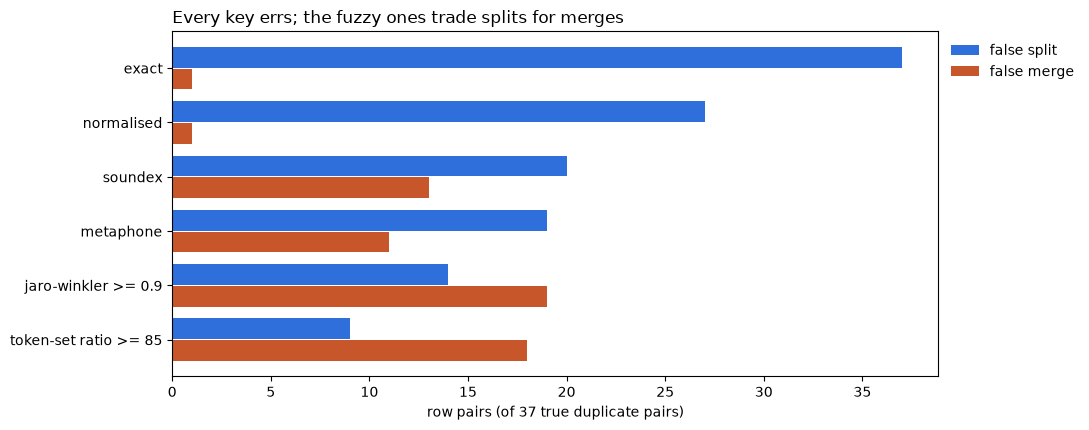

In [9]:
names = list(NAMES)
sp = [len(r["per"][n]["false_splits"]) for n in names]
mg = [len(r["per"][n]["false_merges"]) for n in names]
fig, ax = plt.subplots(figsize=(11, 4.4))
y = list(range(len(names)))
ax.barh([v - 0.2 for v in y], sp, height=0.38, color="#2f6fdb", label="false split")
ax.barh([v + 0.2 for v in y], mg, height=0.38, color="#c8562b", label="false merge")
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlabel(f"row pairs (of {r['ceiling']['true_pairs']} true duplicate pairs)")
ax.set_title("Every key errs; the fuzzy ones trade splits for merges", loc="left")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- The key is not a preprocessing step: it decides how many customers the table has (44 to 19 here, truth 23).
- Exact and normalised keys only split; phonetic and fuzzy keys buy fewer splits with merges of different people.
- A fuzzy threshold is judged pair by pair, but the table is clustered, and clusters join rows that never matched.
- No threshold reaches zero errors, and 7 of 37 true pairs are beyond every key: label a sample, count both errors,
  and route the ambiguous band to a person, as `dedup-pipeline` does after this choice is made.

## 9. Try your own

In [10]:
# for a, b in [("Jonathan Smith", "Jon Smith"), ("Catherine Lee", "Kathryn Lee"), ("Sam Ng", "Sam Ngo")]:
#     print(a, "|", b, {n: f(a) == f(b) for n, f in ROW_KEYS.items()},
#           {n: round(sim(a, b), 3) for n, (sim, t) in PAIR_KEYS.items()})

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version keys your own
names under all six schemes: `pip install -r requirements.txt && streamlit run app.py`.